In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_wine
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

In [ ]:
#Load dataset and split training/testing data
data = load_wine(as_frame=True)

df = data.frame
df = df[df["target"] < 2]

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Features:", X.shape[1])
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Classes:", list(data.target_names[:2]))

Features: 13
Training samples: 104
Testing samples: 26
Classes: [np.str_('class_0'), np.str_('class_1')]


In [ ]:
#Train the Naive Bayes model
model = GaussianNB()

model.fit(X_train, y_train)

predictions = model.predict(X_test)

probabilities = model.predict_proba(X_test)

In [ ]:
#Display class priors and posterior probabilities
print("Class priors:")

print(
    pd.Series(
        model.class_prior_,
        index=data.target_names[:2]
    ).round(4)
)

print("\nFirst five posterior probability predictions:")

probability_table = pd.DataFrame(
    probabilities,
    columns=[
        f"P({class_name})"
        for class_name in data.target_names[:2]
    ]
)

print(probability_table.head().round(4))

Class priors:
class_0    0.4519
class_1    0.5481
dtype: float64

First five posterior probability predictions:
   P(class_0)  P(class_1)
0      0.9908      0.0092
1      1.0000      0.0000
2      0.0000      1.0000
3      0.0000      1.0000
4      0.0000      1.0000


In [ ]:
#Evaluate the classifier
metrics = pd.DataFrame({
    "Metric": ["Accuracy", "F1 score"],
    "Value": [
        accuracy_score(y_test, predictions),
        f1_score(y_test, predictions)
    ]
}).set_index("Metric")

print(metrics.round(4))

           Value
Metric          
Accuracy  0.9615
F1 score  0.9630


In [ ]:
#Classification report and confusion matrix
print(
    classification_report(
        y_test,
        predictions,
        target_names=data.target_names[:2]
    )
)

matrix = confusion_matrix(y_test, predictions)

print("Confusion matrix:")
print(matrix)

              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       1.00      0.93      0.96        14

    accuracy                           0.96        26
   macro avg       0.96      0.96      0.96        26
weighted avg       0.96      0.96      0.96        26

Confusion matrix:
[[12  0]
 [ 1 13]]


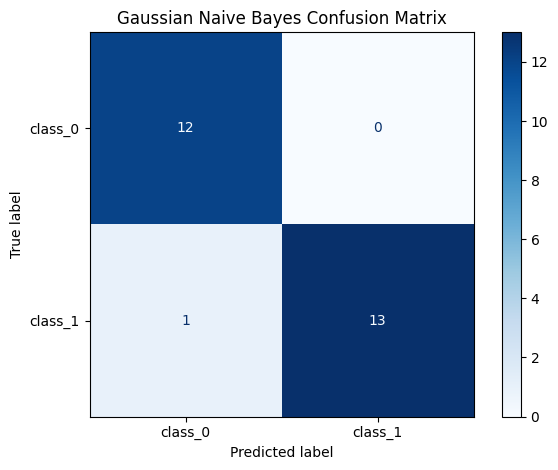

In [ ]:
#Visualize the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=data.target_names[:2]
)

display.plot(cmap="Blues", values_format="d")

plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.tight_layout()
plt.show()